### Introduction

Sentiment Analysis is a Natural Language Processing (NLP) task that involves analyzing textual data to identify and 

classify opinions as positive or negative. This project aims to develop a machine learning-based sentiment 

classification system using TF-IDF for text feature extraction and Multinomial Naive Bayes and Logistic Regression 

algorithms for classification. The system is trained on movie reviews and evaluated using various performance 

metrics to determine its effectiveness in predicting sentiment from user-provided text.

Import Libraries

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/selam/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/selam/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/selam/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/selam/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/selam/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/selam/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

Load and Inspect dataset

In [4]:
df = pd.read_csv('../NLP_Sentiment_Classification_on_Customer_Reviews/data/sentiment_reviews.csv')

df.head()

,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


In [5]:
df.shape

(10, 3)

In [6]:
df.columns

Index(['review_id', 'review_text', 'sentiment'], dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes


In [8]:
df['sentiment'].value_counts()

sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Exploratory Data Analysis (EDA)

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [11]:
df.duplicated().sum()

np.int64(0)

- There are no null or duplicated values.

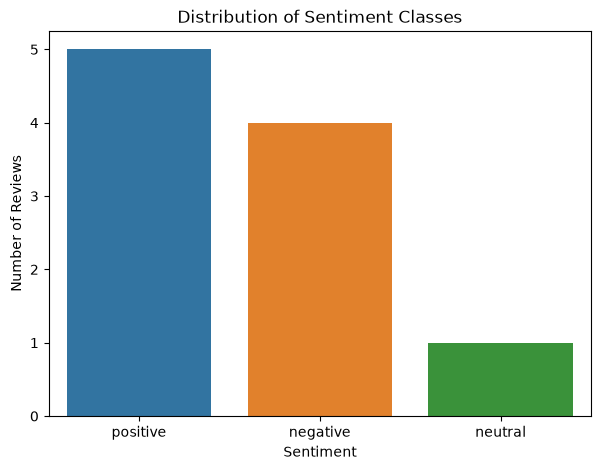

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='sentiment',
    hue='sentiment'
)

plt.title('Distribution of Sentiment Classes')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

- The dataset is not balanced as there is a large number of postive sentiments as compared to the negative and neutral.

In [14]:
# Review Length
df['review_length'] = df['review_text'].apply(
    lambda x: len(str(x).split())
)

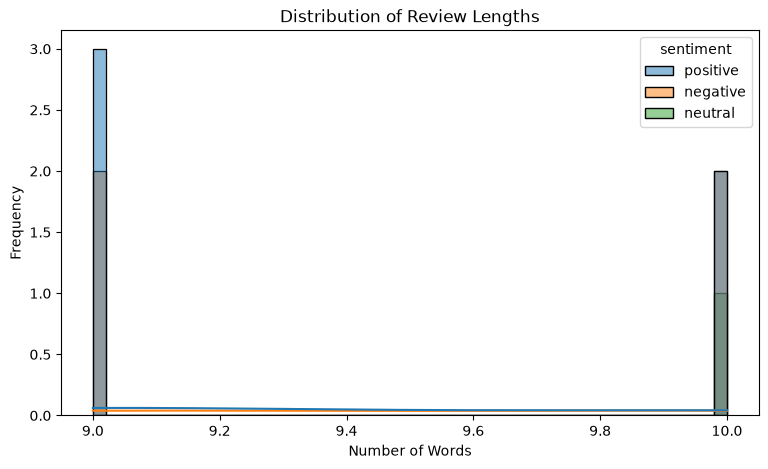

In [15]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='review_length',
    hue='sentiment',
    bins=50,
    kde=True
)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.show()